In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import math as m
from scipy.integrate import solve_ivp

In [2]:
### Parameters ###

DH_A = -45 ## kJ/mol
F_A0 = 1 ## kmol/h
P = 2 ## bar
T0 = 500 ## K
R = 8.314 ## J/mol.K
Cp = 2 ## kJ/kg.K
d_R = 0.03 ## m
l = 3 ## m
Ma = 50 ## kg/kmol


Conversion en sortie : 71.58%
Température en sortie : 822.1 K


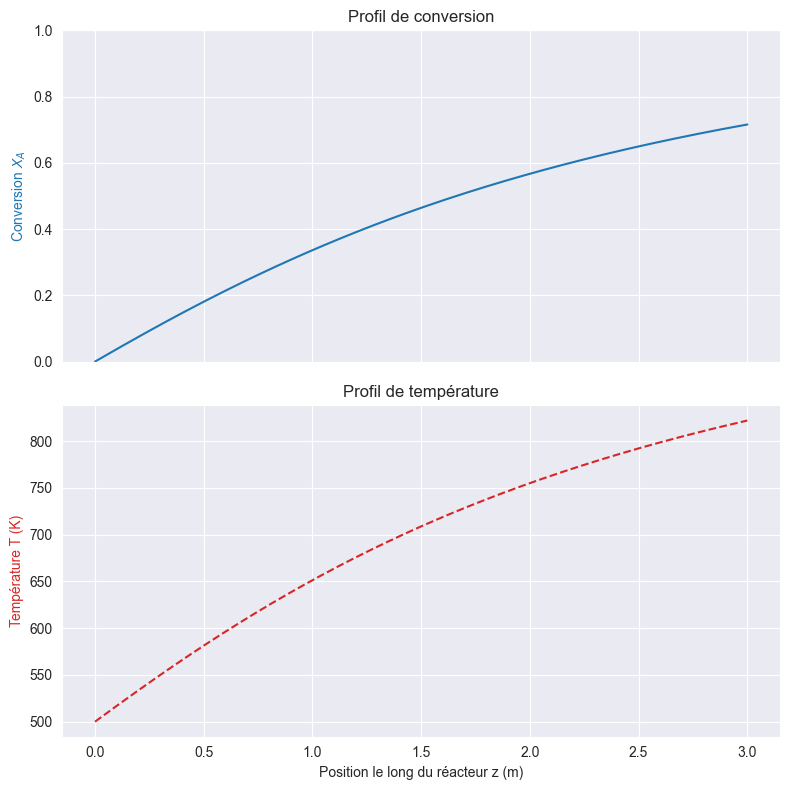

In [3]:
from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Adiabatic reactor 
# Section du réacteur
Ac = np.pi * (d_R**2) / 4

# Conversion d'unités pour cohérence (J, mol, Pa)
P_Pa = P * 1e5             # 2 bar -> 200 000 Pa
F_A0_mol = F_A0 * 1000     # Le flux initial F_A0 : 1 kmol/h -> 1000 mol/h
DH_A_J = DH_A * 1000       # -45 kJ/mol -> -45000 J/mol

# Conversion du Cp (kJ/kg.K -> J/kg.K) multiplié par la masse molaire Ma (kg/kmol)
Cp_mol = (Cp * 1000) * Ma/1000  # J/mol.K     

def systeme_pfr(z, y):
    X_A, T_z = y

    # Évaluation locale de k et C_A
    k_local = 2*10**5 * np.exp(-12000/(R*T_z))
    C_A_local = (P_Pa / (R * T_z)) * ((1 - X_A) / (1 + X_A))

    r_A_local = k_local * C_A_local

    # EDO 1 : Bilan de matière (utilise F_A0 constant)
    dX_dz = (r_A_local * Ac) / F_A0_mol

    # EDO 2 : Bilan d'énergie (utilise F_A0 constant)
    dT_dz = (r_A_local * (-DH_A_J) * Ac) / (F_A0_mol * Cp_mol)

    return [dX_dz, dT_dz]

# Résolution numérique entre z=0 et z=l
sol = solve_ivp(systeme_pfr, [0, l], [0.0, T0], method='RK45', dense_output=True)

# Récupération des données pour le tracé
z_eval = np.linspace(0, l, 200)
X_out, T_out = sol.sol(z_eval)

print(f"Conversion en sortie : {X_out[-1]:.2%}")
print(f"Température en sortie : {T_out[-1]:.1f} K")

# Tracé graphique (2 graphiques séparés)
sns.set_style("darkgrid")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# Graphique 1 : Conversion
color1 = 'tab:blue'
ax1.plot(z_eval, X_out, color=color1, label='$X_A$')
ax1.set_ylabel('Conversion $X_A$', color=color1)
ax1.set_ylim([0, 1])
ax1.set_title('Profil de conversion')

# Graphique 2 : Température
color2 = 'tab:red'
ax2.plot(z_eval, T_out, color=color2, linestyle='--', label='Température')
ax2.set_xlabel('Position le long du réacteur z (m)')
ax2.set_ylabel('Température T (K)', color=color2)
ax2.set_title('Profil de température')

fig.tight_layout()
plt.show()